# V29: fixed 60/40 prior failed the CPU guard

One normalized60%Gemma/40%alignedLlama candidate, no reverse pass, no fitting.
Uniform gain versus H60 fell below the fixed−0.005guard; no GPU qualification
or official submission. Original-training-overlapping, previously inspected
cohorts: descriptive results only, not independent CV or a hidden-score forecast.
[Protocol](../docs/SPAN_029_PLAN.md) · [Result](../docs/SPAN_029_RESULTS.md).

,cohort,rows,prompt_groups,H60_loss,base50_loss,candidate60_loss,gain_vs_H60,removal_gain,weight_gain,group95_low,group95_high
0,control,256,256,0.598234,0.599429,0.608793,-0.010558,-0.001194,-0.009364,-0.015122,-0.006093
1,uniform,512,512,0.652988,0.654242,0.663895,-0.010907,-0.001254,-0.009653,-0.013916,-0.007869
2,long,64,64,0.896484,0.896528,0.897276,-0.000792,-0.000043,-0.000749,-0.009015,0.007399


,cohort,class,gain_vs_H60
0,control,winner_model_a,-0.014150
1,control,winner_model_b,-0.008725
2,control,winner_tie,-0.008250
3,uniform,winner_model_a,-0.012825
4,uniform,winner_model_b,-0.010338
5,uniform,winner_tie,-0.009651
6,long,winner_model_a,-0.010089
7,long,winner_model_b,-0.000026
8,long,winner_tie,0.010114


Decision: stop_gross_regression ; fixed gross threshold: -0.005
CPU elapsed: 1.4108510247897357 seconds / 300
Only one quality variant. Original training overlap; no independent CV or hidden forecast.


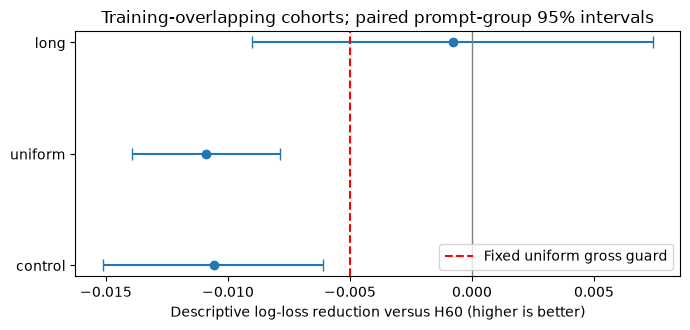

resource_close.json {'at': '2026-11-08T22:12:28.907873+00:00', 'quota': {'used_seconds': 31657.474, 'reserved_seconds': 0.0, 'allowed_seconds': 108000.0, 'refresh_time': '2026-11-14 00:00:00', 'paid_scaling': False, 'remaining_seconds': 76342.526}, 'all_official_terminal': True, 'official_receipts': 7, 'new_span_gpu_executions': 0, 'inherited_full_inventory_sha256': '0242bf47de2569d3126a36b9988a68f6888af9fd82f5ff753c0ddd89acdf6dd0', 'fresh_full_inventory': False}
final_leaderboard.json {'observed_at': '2026-11-08T22:12:37.058076+00:00', 'complete': True, 'team_id': 17244411, 'rank': 23, 'teams': 310, 'score': 0.82987, 'rank19_score': 0.82915, 'rank20_score': 0.82915, 'leader_score': 0.82692, 'target_achieved': False, 'latest_team_submission_date': '2026-11-07T20:07:11.890Z', 'pagination': {'complete': True, 'pages': 4, 'rejected_pages': []}, 'source_sha256': {'scripts/observe_leaderboard.py': '42831e74ff03295144dbbd3067bc9c8d7e4f066136ad889557e5c9895694e18c', 'src/arena/leaderboard.py'

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_029';r=json.loads((PUB/'quality_replay.json').read_text())
rows=[];classes=[]
for name,c in r['cohorts'].items():
 v,w,d=c['versus_incumbent'],c['weight_ablation'],c['removal'];lo,hi=v['paired_group95']
 rows.append({'cohort':name,'rows':c['rows'],'prompt_groups':c['prompt_groups'],
  'H60_loss':v['baseline']['log_loss'],'base50_loss':w['baseline']['log_loss'],
  'candidate60_loss':v['candidate']['log_loss'],'gain_vs_H60':v['loss_reduction'],
  'removal_gain':d['loss_reduction'],'weight_gain':w['loss_reduction'],'group95_low':lo,'group95_high':hi})
 for label,gain in v['class_loss_reduction'].items():classes.append({'cohort':name,'class':label,'gain_vs_H60':gain})
table=pd.DataFrame(rows);display(table);display(pd.DataFrame(classes))
print('Decision:',r['decision'],'; fixed gross threshold:',r['fixed_gross_regression_threshold'])
print('CPU elapsed:',r['elapsed_cpu_seconds'],'seconds /',r['cpu_cap_seconds'])
print('Only one quality variant. Original training overlap; no independent CV or hidden forecast.')
fig,ax=plt.subplots(figsize=(7,3.4));x=table.gain_vs_H60.to_numpy()
ax.errorbar(x,table.cohort,xerr=[x-table.group95_low.to_numpy(),table.group95_high.to_numpy()-x],fmt='o',capsize=4)
ax.axvline(0,color='grey',linewidth=1);ax.axvline(-.005,color='red',linestyle='--',label='Fixed uniform gross guard')
ax.set_xlabel('Descriptive log-loss reduction versus H60 (higher is better)')
ax.set_title('Training-overlapping cohorts; paired prompt-group 95% intervals');ax.legend();fig.tight_layout()
ROOT=Path.home()/'database/llm_classification_finetuning/runs/span_029';(ROOT/'figures').mkdir(exist_ok=True)
fig.savefig(ROOT/'figures/fixed_prior_gains.png',dpi=160,bbox_inches='tight');plt.show()
for name in ['resource_close.json','final_leaderboard.json']:
 p=PUB/name
 if p.exists():print(name,json.loads(p.read_text()))
print('H75 stopped. Prospective40/60follow-up is queued separately; no new candidate probability computed here.')